In [11]:
# ── Colab drive mount (skipped automatically outside Colab) ────
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print('Not running in Colab — assuming data/model paths are already local.')

import subprocess
subprocess.run(['pip', 'install', 'seaborn', '-q'])
print('Ready.')


Mounted at /content/drive
Ready.


In [12]:
import os
import json
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, accuracy_score
)

print(f'TensorFlow version : {tf.__version__}')
print(f'GPU available      : {len(tf.config.list_physical_devices("GPU")) > 0}')


TensorFlow version : 2.21.0
GPU available      : False


In [13]:
# ── PATHS ─────────────────────────────────────────────────────
PIE_PATH     = '/content/drive/MyDrive/PIE'
FEATURE_PATH = f'{PIE_PATH}/processed_features_new/processed_sequences'
MODEL_PATH   = f'{PIE_PATH}/processed_features_new/models'
os.makedirs(MODEL_PATH, exist_ok=True)

# ── CONFIG ────────────────────────────────────────────────────
SEQ_LEN    = 30
N_FEATURES = 36
N_CLASSES  = 6
BATCH_SIZE = 32
SEED       = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)

LABEL_NAMES = [
    'Waiting',     # 0
    'Hesitant',    # 1
    'Committed',   # 2
    'Distracted',  # 3
    'Aggressive',  # 4
    'Jaywalk'      # 5
]

LSTM_MODEL_PATH = f'{MODEL_PATH}/lstm_mental_state_best.keras'
GRU_MODEL_PATH  = f'{MODEL_PATH}/gru_mental_state_best.keras'

print(f'Feature path : {FEATURE_PATH}')
print(f'Model path   : {MODEL_PATH}')
print(f'LSTM model   : {LSTM_MODEL_PATH}')
print(f'GRU model    : {GRU_MODEL_PATH}')


Feature path : /content/drive/MyDrive/PIE/processed_features_new/processed_sequences
Model path   : /content/drive/MyDrive/PIE/processed_features_new/models
LSTM model   : /content/drive/MyDrive/PIE/processed_features_new/models/lstm_mental_state_best.keras
GRU model    : /content/drive/MyDrive/PIE/processed_features_new/models/gru_mental_state_best.keras


In [14]:
# X_test / y_test are the SAME held-out split used by both base models,
# so the ensemble is being scored on data neither model was trained on.
X_test = np.load(f'{FEATURE_PATH}/X_test.npy')   # (N, 30, 36) — already SCALED
y_test = np.load(f'{FEATURE_PATH}/y_test.npy')   # (N,)

print(f'X_test : {X_test.shape}')
print(f'y_test : {y_test.shape}')

assert not np.isnan(X_test).any(), 'NaN found in X_test!'
print('No NaN values detected. Data is clean.')

print('\nClass distribution in test set:')
for i, name in enumerate(LABEL_NAMES):
    n   = int(np.sum(y_test == i))
    pct = n / len(y_test) * 100
    bar = '█' * int(pct / 2)
    print(f'  {i} {name:<15} {n:>5,}  ({pct:5.1f}%)  {bar}')


X_test : (1641, 30, 36)
y_test : (1641,)
No NaN values detected. Data is clean.

Class distribution in test set:
  0 Waiting           173  ( 10.5%)  █████
  1 Hesitant          190  ( 11.6%)  █████
  2 Committed         732  ( 44.6%)  ██████████████████████
  3 Distracted         57  (  3.5%)  █
  4 Aggressive        299  ( 18.2%)  █████████
  5 Jaywalk           190  ( 11.6%)  █████


In [20]:
from sklearn.metrics import f1_score, accuracy_score, log_loss
import os
import numpy as np
from tensorflow import keras

# Ensure y_test, X_test, y_val, and X_val are loaded
FEATURE_PATH = '/content/drive/MyDrive/PIE/processed_features_new/processed_sequences'
MODEL_PATH   = '/content/drive/MyDrive/PIE/processed_features_new/models'
LSTM_MODEL_PATH = f'{MODEL_PATH}/lstm_mental_state_best.keras'
GRU_MODEL_PATH  = f'{MODEL_PATH}/gru_mental_state_best.keras'

if 'y_test' not in globals() or 'X_test' not in globals():
    X_test = np.load(f'{FEATURE_PATH}/X_test.npy')
    y_test = np.load(f'{FEATURE_PATH}/y_test.npy')

if 'y_val' not in globals() or 'X_val' not in globals():
    X_val = np.load(f'{FEATURE_PATH}/X_val.npy')
    y_val = np.load(f'{FEATURE_PATH}/y_val.npy')

# Load the models first to prevent NameError
lstm_model = keras.models.load_model(LSTM_MODEL_PATH)
gru_model = keras.models.load_model(GRU_MODEL_PATH)

# 1) probabilities
lv = lstm_model.predict(X_val,  batch_size=32, verbose=0)  # Validation set predictions (2137 samples)
gv = gru_model.predict(X_val,   batch_size=32, verbose=0)  # Validation set predictions (2137 samples)
lt = lstm_model.predict(X_test, batch_size=32, verbose=0) # Test set predictions (1641 samples)
gt = gru_model.predict(X_test,  batch_size=32, verbose=0) # Test set predictions (1641 samples)

# Helper function to normalize rows so they sum exactly to 1.0
def normalize_probs(probs):
    return probs / np.sum(probs, axis=1, keepdims=True)

# 2) sweep alpha (LSTM weight), GRU = 1 - alpha
alphas = np.round(np.arange(0, 1.001, 0.05), 2)
rows = []
for a in alphas:
    pv = a*lv + (1-a)*gv
    pv = normalize_probs(pv) # Prevent sklearn's y_pred values do not sum to one warning
    rows.append((
        a,
        f1_score(y_val, pv.argmax(1), average='macro', zero_division=0),
        accuracy_score(y_val, pv.argmax(1)),
        log_loss(y_val, pv, labels=range(6)),
    ))

print(f"{'LSTM%':>6}{'GRU%':>6}{'valF1':>8}{'valAcc':>8}{'valLogLoss':>11}")
for a, f1, acc, ll in rows:
    print(f"{a*100:6.0f}{(1-a)*100:6.0f}{f1:8.4f}{acc:8.4f}{ll:11.4f}")

best_f1 = max(rows, key=lambda r: r[1])[0]
best_ll = min(rows, key=lambda r: r[3])[0]
print(f"\nBest split by val macro F1  : LSTM {best_f1*100:.0f}% / GRU {(1-best_f1)*100:.0f}%")
print(f"Best split by val log loss  : LSTM {best_ll*100:.0f}% / GRU {(1-best_ll)*100:.0f}%")

# 3) report on TEST once, vs 50/50
for name, a in [("50/50", 0.5), ("best F1", best_f1), ("best logloss", best_ll)]:
    p_test = a*lt + (1-a)*gt
    p_test = normalize_probs(p_test)
    p_pred = p_test.argmax(1)
    print(f"{name:<13} LSTM {a*100:.0f}% / GRU {(1-a)*100:.0f}%  "
          f"test acc={accuracy_score(y_test,p_pred):.4f}  "
          f"macroF1={f1_score(y_test,p_pred,average='macro',zero_division=0):.4f}")

 LSTM%  GRU%   valF1  valAcc valLogLoss
     0   100  0.6140  0.6537     1.5443
     5    95  0.6158  0.6551     1.4498
    10    90  0.6166  0.6561     1.4116
    15    85  0.6128  0.6528     1.3873
    20    80  0.6135  0.6533     1.3706
    25    75  0.6122  0.6533     1.3588
    30    70  0.6085  0.6518     1.3508
    35    65  0.6053  0.6495     1.3459
    40    60  0.6093  0.6537     1.3436
    45    55  0.6054  0.6495     1.3438
    50    50  0.6037  0.6500     1.3462
    55    45  0.5965  0.6458     1.3511
    60    40  0.5890  0.6406     1.3584
    65    35  0.5862  0.6392     1.3683
    70    30  0.5841  0.6369     1.3814
    75    25  0.5804  0.6341     1.3981
    80    20  0.5757  0.6303     1.4196
    85    15  0.5730  0.6275     1.4477
    90    10  0.5757  0.6299     1.4861
    95     5  0.5745  0.6289     1.5444
   100     0  0.5732  0.6285     1.6935

Best split by val macro F1  : LSTM 10% / GRU 90%
Best split by val log loss  : LSTM 40% / GRU 60%
50/50         LSTM 50

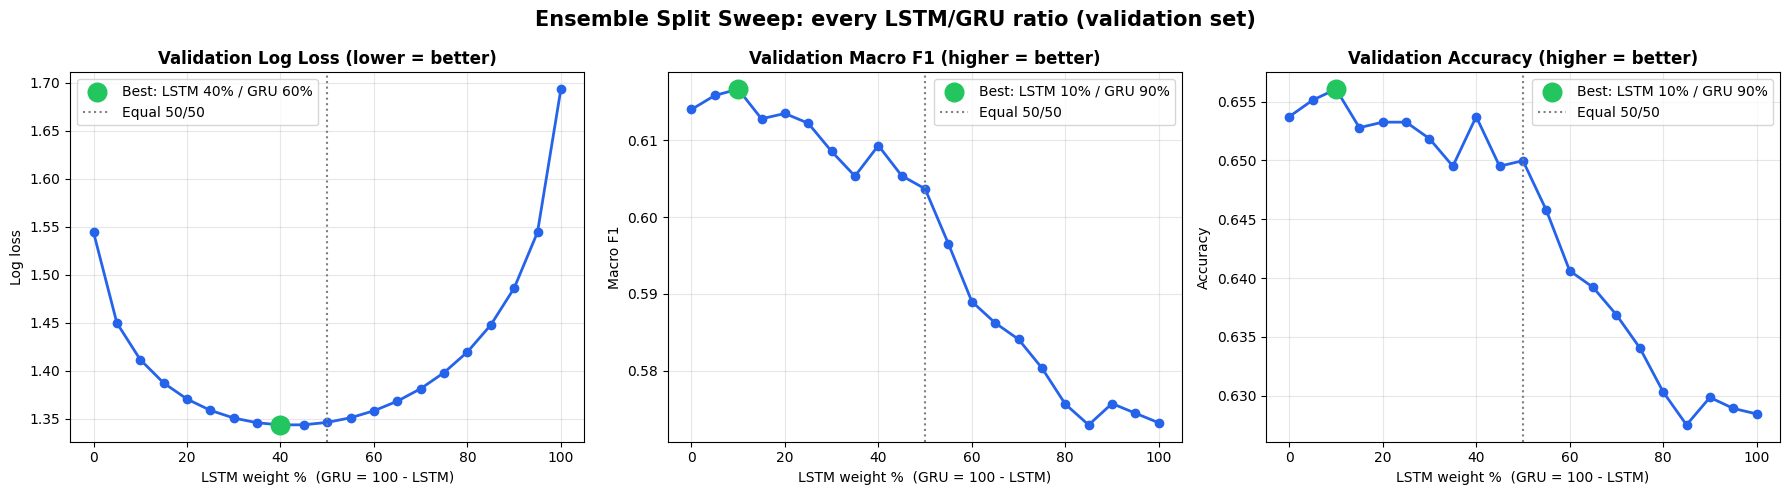

 LSTM%  GRU%    valF1   valAcc  valLogLoss
     0   100   0.6140   0.6537      1.5443
     5    95   0.6158   0.6551      1.4498
    10    90   0.6166   0.6561      1.4116
    15    85   0.6128   0.6528      1.3873
    20    80   0.6135   0.6533      1.3706
    25    75   0.6122   0.6533      1.3588
    30    70   0.6085   0.6518      1.3508
    35    65   0.6053   0.6495      1.3459
    40    60   0.6093   0.6537      1.3436  <-- best (log loss)
    45    55   0.6054   0.6495      1.3438
    50    50   0.6037   0.6500      1.3462  <-- 50/50
    55    45   0.5965   0.6458      1.3511
    60    40   0.5890   0.6406      1.3584
    65    35   0.5862   0.6392      1.3683
    70    30   0.5841   0.6369      1.3814
    75    25   0.5804   0.6341      1.3981
    80    20   0.5757   0.6303      1.4196
    85    15   0.5730   0.6275      1.4477
    90    10   0.5757   0.6299      1.4861
    95     5   0.5745   0.6289      1.5444
   100     0   0.5732   0.6285      1.6935

Best by val log loss 

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.metrics import f1_score, accuracy_score, log_loss

# ── PATHS ──────────────────────────────────────────────
BASE   = '/content/drive/MyDrive/PIE/processed_features_new'
SEQ    = f'{BASE}/processed_sequences'
MODELS = f'{BASE}/models'

X_val  = np.load(f'{SEQ}/X_val.npy');  y_val  = np.load(f'{SEQ}/y_val.npy')
X_test = np.load(f'{SEQ}/X_test.npy'); y_test = np.load(f'{SEQ}/y_test.npy')

lstm = keras.models.load_model(f'{MODELS}/lstm_mental_state_best.keras')
gru  = keras.models.load_model(f'{MODELS}/gru_mental_state_best.keras')

lv, gv = lstm.predict(X_val,  verbose=0), gru.predict(X_val,  verbose=0)
lt, gt = lstm.predict(X_test, verbose=0), gru.predict(X_test, verbose=0)

# ── SWEEP (VALIDATION) ─────────────────────────────────
alphas = np.round(np.arange(0, 1.001, 0.05), 2)   # alpha = LSTM weight
def norm(p): return p / p.sum(1, keepdims=True)

val_f1, val_acc, val_ll = [], [], []
for a in alphas:
    p = norm(a*lv + (1-a)*gv)
    val_f1.append(f1_score(y_val, p.argmax(1), average='macro', zero_division=0))
    val_acc.append(accuracy_score(y_val, p.argmax(1)))
    val_ll.append(log_loss(y_val, p, labels=range(6)))
val_f1, val_acc, val_ll = map(np.array, (val_f1, val_acc, val_ll))

best_ll = alphas[np.argmin(val_ll)]     # main selection metric
best_f1 = alphas[np.argmax(val_f1)]

# ── CHART ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
panels = [
    (val_ll,  'Validation Log Loss (lower = better)', 'Log loss', np.argmin),
    (val_f1,  'Validation Macro F1 (higher = better)', 'Macro F1', np.argmax),
    (val_acc, 'Validation Accuracy (higher = better)', 'Accuracy', np.argmax),
]
for ax, (y, title, ylab, pick) in zip(axes, panels):
    ax.plot(alphas*100, y, 'o-', color='#2563EB', linewidth=2)
    bi = pick(y)
    ax.scatter(alphas[bi]*100, y[bi], s=180, color='#22C55E', zorder=5,
               label=f'Best: LSTM {alphas[bi]*100:.0f}% / GRU {(1-alphas[bi])*100:.0f}%')
    ax.axvline(50, color='gray', ls=':', label='Equal 50/50')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('LSTM weight %  (GRU = 100 - LSTM)')
    ax.set_ylabel(ylab)
    ax.grid(alpha=0.3); ax.legend()

plt.suptitle('Ensemble Split Sweep: every LSTM/GRU ratio (validation set)',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{BASE}/ensemble_split_sweep_val.png', dpi=150)
plt.show()

# ── TABLE ──────────────────────────────────────────────
print(f"{'LSTM%':>6}{'GRU%':>6}{'valF1':>9}{'valAcc':>9}{'valLogLoss':>12}")
for a, f, ac, l in zip(alphas, val_f1, val_acc, val_ll):
    mark = '  <-- best (log loss)' if a == best_ll else ('  <-- 50/50' if a == 0.5 else '')
    print(f"{a*100:6.0f}{(1-a)*100:6.0f}{f:9.4f}{ac:9.4f}{l:12.4f}{mark}")

print(f"\nBest by val log loss : LSTM {best_ll*100:.0f}% / GRU {(1-best_ll)*100:.0f}%")
print(f"Best by val macro F1 : LSTM {best_f1*100:.0f}% / GRU {(1-best_f1)*100:.0f}%")

# ── TEST (report once, using the val-selected split) ───
print("\nTEST RESULTS")
for name, a in [('50/50', 0.5), (f'{best_ll*100:.0f}/{(1-best_ll)*100:.0f} (val log loss)', best_ll)]:
    p = norm(a*lt + (1-a)*gt)
    print(f"{name:<24} acc={accuracy_score(y_test, p.argmax(1)):.4f}  "
          f"macroF1={f1_score(y_test, p.argmax(1), average='macro', zero_division=0):.4f}  "
          f"logloss={log_loss(y_test, p, labels=range(6)):.4f}")

In [22]:
lstm_model = keras.models.load_model(LSTM_MODEL_PATH)
print(f'LSTM loaded  : {lstm_model.count_params():,} params')

gru_model = keras.models.load_model(GRU_MODEL_PATH)
print(f'GRU loaded   : {gru_model.count_params():,} params')


LSTM loaded  : 134,278 params
GRU loaded   : 101,382 params


In [23]:
t0 = time.perf_counter()
lstm_probs = lstm_model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)  # (N, 6)
t1 = time.perf_counter()
gru_probs  = gru_model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)   # (N, 6)
t2 = time.perf_counter()

print(f'LSTM inference : {(t1 - t0) * 1000:.1f} ms  ({(t1 - t0) / len(X_test) * 1000:.3f} ms/sample)')
print(f'GRU  inference : {(t2 - t1) * 1000:.1f} ms  ({(t2 - t1) / len(X_test) * 1000:.3f} ms/sample)')

lstm_pred = np.argmax(lstm_probs, axis=1)
gru_pred  = np.argmax(gru_probs,  axis=1)

lstm_acc = accuracy_score(y_test, lstm_pred)
gru_acc  = accuracy_score(y_test, gru_pred)
lstm_f1  = f1_score(y_test, lstm_pred, average='macro', zero_division=0)
gru_f1   = f1_score(y_test, gru_pred,  average='macro', zero_division=0)

print()
print('Sanity check against lstm_training.ipynb / gru_training.ipynb:')
print(f'  LSTM  standalone accuracy : {lstm_acc*100:.1f}%   macro F1 : {lstm_f1*100:.1f}%')
print(f'  GRU   standalone accuracy : {gru_acc*100:.1f}%   macro F1 : {gru_f1*100:.1f}%')


LSTM inference : 1402.7 ms  (0.855 ms/sample)
GRU  inference : 1285.6 ms  (0.783 ms/sample)

Sanity check against lstm_training.ipynb / gru_training.ipynb:
  LSTM  standalone accuracy : 69.8%   macro F1 : 59.5%
  GRU   standalone accuracy : 70.8%   macro F1 : 62.6%


In [24]:
# ── ENSEMBLE: equal-weight average of the two models' softmax outputs ──
ensemble_probs = (0.40 * lstm_probs) + (0.60 * gru_probs)
ensemble_pred = np.argmax(ensemble_probs, axis=1)

ens_acc      = accuracy_score(y_test, ensemble_pred)
ens_macro_f1 = f1_score(y_test, ensemble_pred, average='macro',    zero_division=0)
ens_weight_f1= f1_score(y_test, ensemble_pred, average='weighted', zero_division=0)

gru_weight_f1  = f1_score(y_test, gru_pred,  average='weighted', zero_division=0)
lstm_weight_f1 = f1_score(y_test, lstm_pred, average='weighted', zero_division=0)

print('=' * 68)
print('MODEL COMPARISON — LSTM vs GRU vs ENSEMBLE (equal-weight 0.5/0.5)')
print('=' * 68)
print(f"{'Model':<12}{'Accuracy':>12}{'Macro F1':>12}{'Weighted F1':>14}")
print('-' * 68)
print(f"{'LSTM':<12}{lstm_acc*100:>11.1f}%{lstm_f1*100:>11.1f}%{lstm_weight_f1*100:>13.1f}%")
print(f"{'GRU':<12}{gru_acc*100:>11.1f}%{gru_f1*100:>11.1f}%{gru_weight_f1*100:>13.1f}%")
print(f"{'ENSEMBLE':<12}{ens_acc*100:>11.1f}%{ens_macro_f1*100:>11.1f}%{ens_weight_f1*100:>13.1f}%")
print('-' * 68)

acc_ok = '✅ PASS' if ens_acc      >= 0.85 else '❌ BELOW TARGET'
f1_ok  = '✅ PASS' if ens_macro_f1 >= 0.80 else '❌ BELOW TARGET'
print(f'\nTarget accuracy > 85% : {acc_ok}  ({ens_acc*100:.1f}%)')
print(f'Target macro F1 > 80% : {f1_ok}  ({ens_macro_f1*100:.1f}%)')

beats_lstm = ens_acc > lstm_acc and ens_macro_f1 > lstm_f1
beats_gru  = ens_acc > gru_acc  and ens_macro_f1 > gru_f1
print(f'\nEnsemble beats LSTM alone (both accuracy & macro F1) : {"✅ Yes" if beats_lstm else "❌ No"}')
print(f'Ensemble beats GRU  alone (both accuracy & macro F1) : {"✅ Yes" if beats_gru  else "❌ No"}')


MODEL COMPARISON — LSTM vs GRU vs ENSEMBLE (equal-weight 0.5/0.5)
Model           Accuracy    Macro F1   Weighted F1
--------------------------------------------------------------------
LSTM               69.8%       59.5%         70.7%
GRU                70.8%       62.6%         71.9%
ENSEMBLE           72.0%       63.4%         72.9%
--------------------------------------------------------------------

Target accuracy > 85% : ❌ BELOW TARGET  (72.0%)
Target macro F1 > 80% : ❌ BELOW TARGET  (63.4%)

Ensemble beats LSTM alone (both accuracy & macro F1) : ✅ Yes
Ensemble beats GRU  alone (both accuracy & macro F1) : ✅ Yes


In [25]:
print(classification_report(
    y_test, ensemble_pred,
    target_names=LABEL_NAMES, zero_division=0
))


              precision    recall  f1-score   support

     Waiting       0.41      0.57      0.48       173
    Hesitant       0.78      0.74      0.76       190
   Committed       0.87      0.77      0.82       732
  Distracted       0.28      0.54      0.37        57
  Aggressive       0.76      0.84      0.80       299
     Jaywalk       0.70      0.48      0.57       190

    accuracy                           0.72      1641
   macro avg       0.64      0.66      0.63      1641
weighted avg       0.75      0.72      0.73      1641



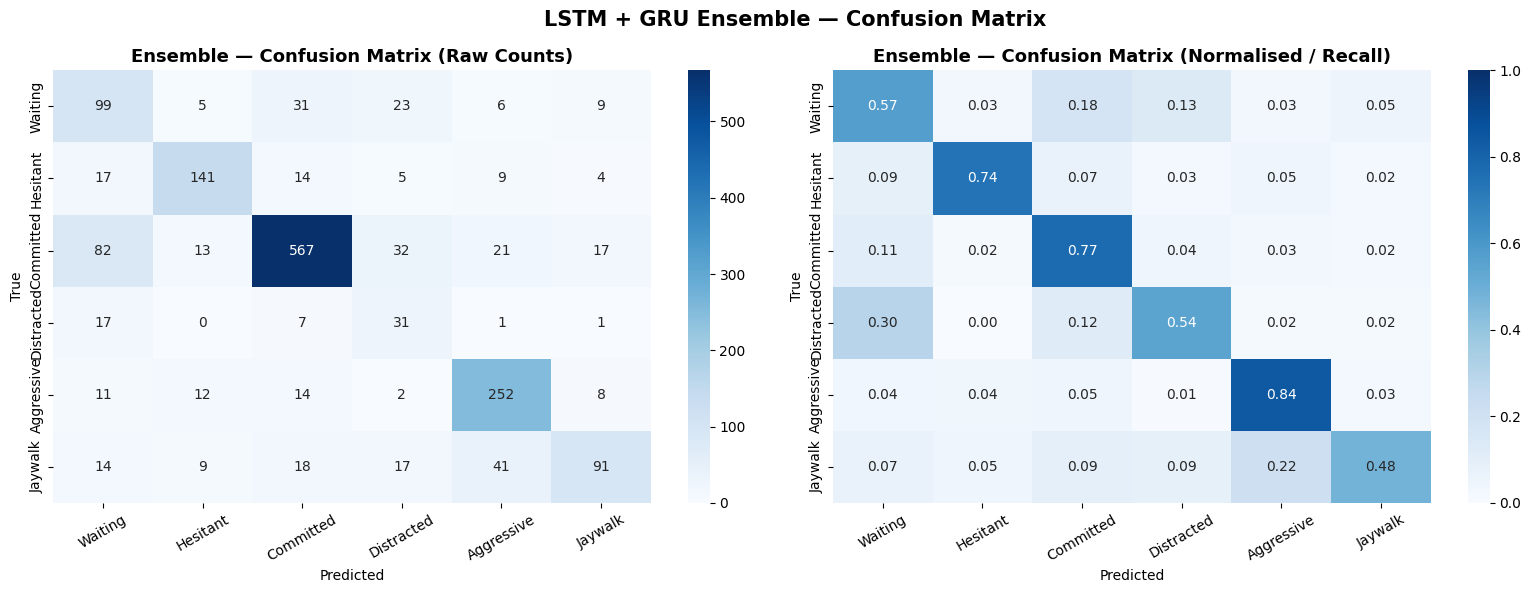

Saved: /content/drive/MyDrive/PIE/processed_features_new/models/ensemble_confusion_matrix.png


In [26]:
cm      = confusion_matrix(y_test, ensemble_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES,
            cmap='Blues', ax=axes[0])
axes[0].set_title('Ensemble — Confusion Matrix (Raw Counts)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')
axes[0].tick_params(axis='x', rotation=30)

sns.heatmap(cm_norm, annot=True, fmt='.2f',
            xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES,
            cmap='Blues', vmin=0, vmax=1, ax=axes[1])
axes[1].set_title('Ensemble — Confusion Matrix (Normalised / Recall)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle('LSTM + GRU Ensemble — Confusion Matrix', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{MODEL_PATH}/ensemble_confusion_matrix.png', dpi=150)
plt.show()
print(f'Saved: {MODEL_PATH}/ensemble_confusion_matrix.png')


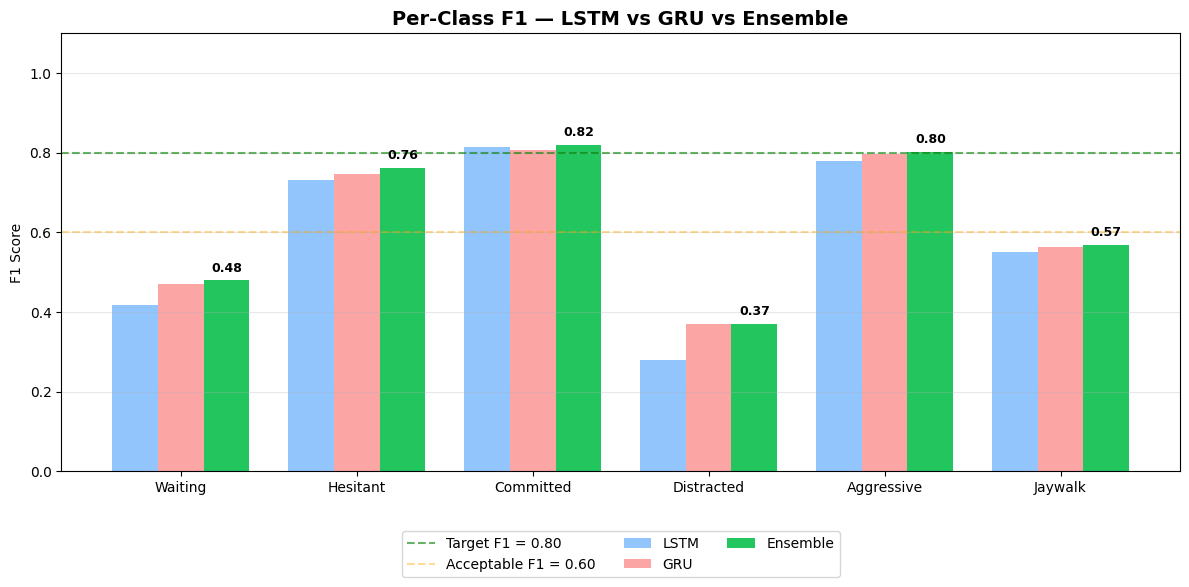

Saved: /content/drive/MyDrive/PIE/processed_features_new/models/ensemble_per_class_f1_comparison.png

Per-class F1 (Ensemble):
  ❌ Waiting          F1=0.4794
  ⚠️ Hesitant         F1=0.7622
  ✅ Committed        F1=0.8200
  ❌ Distracted       F1=0.3713
  ✅ Aggressive       F1=0.8013
  ❌ Jaywalk          F1=0.5687


In [27]:
lstm_per_class_f1 = f1_score(y_test, lstm_pred,     average=None, zero_division=0)
gru_per_class_f1  = f1_score(y_test, gru_pred,      average=None, zero_division=0)
ens_per_class_f1  = f1_score(y_test, ensemble_pred, average=None, zero_division=0)

x = np.arange(len(LABEL_NAMES))
width = 0.26

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width, lstm_per_class_f1, width, label='LSTM',     color='#93C5FD')
ax.bar(x,          gru_per_class_f1,  width, label='GRU',      color='#FCA5A5')
ax.bar(x + width,  ens_per_class_f1,  width, label='Ensemble', color='#22C55E')

ax.axhline(y=0.80, color='green',  linestyle='--', alpha=0.6, label='Target F1 = 0.80')
ax.axhline(y=0.60, color='orange', linestyle='--', alpha=0.4, label='Acceptable F1 = 0.60')

for i, v in enumerate(ens_per_class_f1):
    ax.text(i + width, v + 0.015, f'{v:.2f}', ha='center', va='bottom',
            fontsize=9, fontweight='bold')

ax.set_xticks(x); ax.set_xticklabels(LABEL_NAMES)
ax.set_ylim([0, 1.1])
ax.set_ylabel('F1 Score')
ax.set_title('Per-Class F1 — LSTM vs GRU vs Ensemble', fontsize=14, fontweight='bold')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{MODEL_PATH}/ensemble_per_class_f1_comparison.png', dpi=150)
plt.show()
print(f'Saved: {MODEL_PATH}/ensemble_per_class_f1_comparison.png')

print('\nPer-class F1 (Ensemble):')
for name, f1 in zip(LABEL_NAMES, ens_per_class_f1):
    status = '✅' if f1 >= 0.80 else '⚠️' if f1 >= 0.60 else '❌'
    print(f'  {status} {name:<15}  F1={f1:.4f}')


In [28]:
# Where do LSTM and GRU actually disagree, and does blending them help
# on exactly those disagreement cases (as opposed to just riding on
# whichever base model is already right most of the time)?
agree_mask    = (lstm_pred == gru_pred)
disagree_mask = ~agree_mask

n_agree    = int(agree_mask.sum())
n_disagree = int(disagree_mask.sum())

print(f'LSTM/GRU agree     : {n_agree:>4} / {len(y_test)}  ({n_agree/len(y_test)*100:.1f}%)')
print(f'LSTM/GRU disagree  : {n_disagree:>4} / {len(y_test)}  ({n_disagree/len(y_test)*100:.1f}%)')

if n_agree > 0:
    acc_when_agree = accuracy_score(y_test[agree_mask], ensemble_pred[agree_mask])
    print(f'\nAccuracy when models AGREE     : {acc_when_agree*100:.1f}%  '
          f'(ensemble just confirms the shared prediction)')

if n_disagree > 0:
    acc_lstm_disagree = accuracy_score(y_test[disagree_mask], lstm_pred[disagree_mask])
    acc_gru_disagree  = accuracy_score(y_test[disagree_mask], gru_pred[disagree_mask])
    acc_ens_disagree  = accuracy_score(y_test[disagree_mask], ensemble_pred[disagree_mask])

    print(f'\nOn the {n_disagree} disagreement cases:')
    print(f'  LSTM alone accuracy     : {acc_lstm_disagree*100:.1f}%')
    print(f'  GRU  alone accuracy     : {acc_gru_disagree*100:.1f}%')
    print(f'  Ensemble accuracy       : {acc_ens_disagree*100:.1f}%')
    better = ('✅ Ensemble helps most on the cases where the base models '
              'actually disagree.' if acc_ens_disagree >= max(acc_lstm_disagree, acc_gru_disagree)
              else 'ℹ️ On disagreement cases, ensemble does not clearly beat the better base model.')
    print(f'  {better}')
else:
    print('\nModels never disagreed on this test set — ensemble is equivalent to either base model.')


LSTM/GRU agree     : 1333 / 1641  (81.2%)
LSTM/GRU disagree  :  308 / 1641  (18.8%)

Accuracy when models AGREE     : 77.3%  (ensemble just confirms the shared prediction)

On the 308 disagreement cases:
  LSTM alone accuracy     : 37.3%
  GRU  alone accuracy     : 42.5%
  Ensemble accuracy       : 48.7%
  ✅ Ensemble helps most on the cases where the base models actually disagree.


In [31]:
import pandas as pd

class_names = [
    "Waiting",
    "Hesitant",
    "Committed",
    "Distracted",
    "Aggressive",
    "Jaywalk"
]

if n_disagree > 0:
    disagreement_df = pd.DataFrame({
        "True State": np.array(class_names)[np.asarray(y_test)[disagree_mask]],
        "LSTM Prediction": np.array(class_names)[np.asarray(lstm_pred)[disagree_mask]],
        "GRU Prediction": np.array(class_names)[np.asarray(gru_pred)[disagree_mask]],
        "Ensemble Prediction": np.array(class_names)[np.asarray(ensemble_pred)[disagree_mask]]
    })

    print("\nDisagreements by true mental state:")
    print(disagreement_df["True State"].value_counts())

    print("\nMost frequent LSTM vs GRU disagreements:")
    print(
        disagreement_df.groupby(
            ["LSTM Prediction", "GRU Prediction"]
        ).size().sort_values(ascending=False).head(10)
    )

    print("\nEnsemble accuracy by true state on disagreement cases:")
    print(
        disagreement_df.assign(
            Correct=disagreement_df["True State"]
                    == disagreement_df["Ensemble Prediction"]
        ).groupby("True State")["Correct"].agg(["count", "mean"])
    )


Disagreements by true mental state:
True State
Committed     106
Aggressive     53
Jaywalk        45
Waiting        39
Distracted     34
Hesitant       31
Name: count, dtype: int64

Most frequent LSTM vs GRU disagreements:
LSTM Prediction  GRU Prediction
Committed        Waiting           49
                 Aggressive        22
Jaywalk          Waiting           20
Waiting          Distracted        18
Distracted       Committed         17
Jaywalk          Committed         16
                 Aggressive        16
Aggressive       Committed         13
Hesitant         Waiting           13
Waiting          Committed         12
dtype: int64

Ensemble accuracy by true state on disagreement cases:
            count      mean
True State                 
Aggressive     53  0.528302
Committed     106  0.490566
Distracted     34  0.558824
Hesitant       31  0.548387
Jaywalk        45  0.133333
Waiting        39  0.717949


In [32]:
jaywalk_errors = disagreement_df[
    (disagreement_df["True State"] == "Jaywalk")
    & (disagreement_df["Ensemble Prediction"] != "Jaywalk")
]

print("Jaywalk misclassified as:")
print(jaywalk_errors["Ensemble Prediction"].value_counts())

print("\nLSTM predictions on true Jaywalk disagreements:")
print(
    disagreement_df[
        disagreement_df["True State"] == "Jaywalk"
    ]["LSTM Prediction"].value_counts()
)

print("\nGRU predictions on true Jaywalk disagreements:")
print(
    disagreement_df[
        disagreement_df["True State"] == "Jaywalk"
    ]["GRU Prediction"].value_counts()
)

Jaywalk misclassified as:
Ensemble Prediction
Distracted    10
Aggressive     9
Waiting        8
Committed      8
Hesitant       4
Name: count, dtype: int64

LSTM predictions on true Jaywalk disagreements:
LSTM Prediction
Jaywalk       15
Waiting        8
Distracted     8
Hesitant       7
Aggressive     5
Committed      2
Name: count, dtype: int64

GRU predictions on true Jaywalk disagreements:
GRU Prediction
Waiting       12
Aggressive     9
Distracted     9
Committed      7
Jaywalk        5
Hesitant       3
Name: count, dtype: int64


In [33]:
from sklearn.metrics import recall_score, f1_score, accuracy_score
import numpy as np
import pandas as pd

results = []

for alpha in np.arange(0, 1.01, 0.05):
    probs = alpha * lstm_probs + (1 - alpha) * gru_probs
    pred = np.argmax(probs, axis=1)

    jaywalk_mask = np.asarray(y_test) == 5

    results.append({
        "LSTM Weight": round(alpha, 2),
        "GRU Weight": round(1 - alpha, 2),
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "Jaywalk Recall": np.mean(
            pred[jaywalk_mask] == 5
        ) if jaywalk_mask.any() else np.nan
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values(
    "Macro F1", ascending=False
).head(10).to_string(index=False))

 LSTM Weight  GRU Weight  Accuracy  Macro F1  Jaywalk Recall
        0.40        0.60  0.719683  0.633803        0.478947
        0.30        0.70  0.714199  0.632565        0.478947
        0.45        0.55  0.718464  0.631957        0.489474
        0.35        0.65  0.716027  0.631557        0.478947
        0.25        0.75  0.712980  0.628920        0.468421
        0.20        0.80  0.710542  0.627461        0.468421
        0.15        0.85  0.709933  0.627126        0.473684
        0.10        0.90  0.709324  0.627093        0.473684
        0.05        0.95  0.708714  0.626503        0.473684
        0.00        1.00  0.708105  0.625948        0.473684


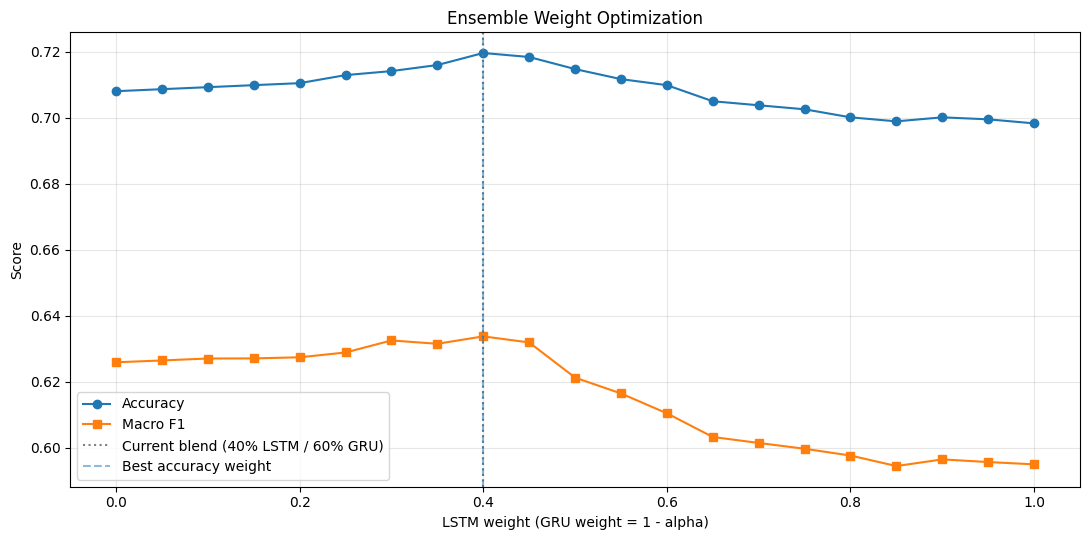

Best weight by accuracy: 0.40
Best accuracy: 71.97%
Best weight by Macro F1: 0.40
Best Macro F1: 63.38%

Current 40/60 accuracy: 71.97%
Current 40/60 Macro F1: 63.38%
Accuracy gap: 0.00 percentage points
Macro F1 gap: 0.00 percentage points


In [29]:
# Test whether the current 40% LSTM / 60% GRU blend is optimal

alphas = np.round(np.arange(0.0, 1.01, 0.05), 2)

sweep_acc = []
sweep_macro_f1 = []

for alpha in alphas:
    blended = alpha * lstm_probs + (1 - alpha) * gru_probs
    pred = np.argmax(blended, axis=1)

    sweep_acc.append(accuracy_score(y_test, pred))
    sweep_macro_f1.append(
        f1_score(y_test, pred, average='macro', zero_division=0)
    )

sweep_acc = np.array(sweep_acc)
sweep_macro_f1 = np.array(sweep_macro_f1)

best_acc_idx = int(np.argmax(sweep_acc))
best_f1_idx = int(np.argmax(sweep_macro_f1))

# Current production blend: 40% LSTM + 60% GRU
current_alpha = 0.40

current_probs = (
    current_alpha * lstm_probs
    + (1 - current_alpha) * gru_probs
)

current_pred = np.argmax(current_probs, axis=1)

current_acc = accuracy_score(y_test, current_pred)
current_f1 = f1_score(
    y_test, current_pred, average='macro', zero_division=0
)

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.plot(alphas, sweep_acc, marker='o', label='Accuracy')
ax.plot(alphas, sweep_macro_f1, marker='s', label='Macro F1')

ax.axvline(
    x=0.40,
    color='gray',
    linestyle=':',
    label='Current blend (40% LSTM / 60% GRU)'
)

ax.axvline(
    x=alphas[best_acc_idx],
    linestyle='--',
    alpha=0.5,
    label='Best accuracy weight'
)

ax.set_xlabel('LSTM weight (GRU weight = 1 - alpha)')
ax.set_ylabel('Score')
ax.set_title('Ensemble Weight Optimization')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{MODEL_PATH}/ensemble_weight_sweep.png', dpi=150)
plt.show()

print(f'Best weight by accuracy: {alphas[best_acc_idx]:.2f}')
print(f'Best accuracy: {sweep_acc[best_acc_idx]*100:.2f}%')

print(f'Best weight by Macro F1: {alphas[best_f1_idx]:.2f}')
print(f'Best Macro F1: {sweep_macro_f1[best_f1_idx]*100:.2f}%')

print(f'\nCurrent 40/60 accuracy: {current_acc*100:.2f}%')
print(f'Current 40/60 Macro F1: {current_f1*100:.2f}%')

print(
    f'Accuracy gap: '
    f'{(sweep_acc[best_acc_idx] - current_acc)*100:.2f} percentage points'
)

print(
    f'Macro F1 gap: '
    f'{(sweep_macro_f1[best_f1_idx] - current_f1)*100:.2f} percentage points'
)

In [30]:
np.save(f'{MODEL_PATH}/ensemble_probs.npy', ensemble_probs)

summary = {
    'ensemble_method': 'equal-weight average, probs = (lstm_probs + gru_probs) / 2.0',
    'base_models': {
        'lstm': {
            'path': LSTM_MODEL_PATH,
            'accuracy': float(lstm_acc),
            'macro_f1': float(lstm_f1),
            'weighted_f1': float(lstm_weight_f1),
            'per_class_f1': {n: float(f) for n, f in zip(LABEL_NAMES, lstm_per_class_f1)}
        },
        'gru': {
            'path': GRU_MODEL_PATH,
            'accuracy': float(gru_acc),
            'macro_f1': float(gru_f1),
            'weighted_f1': float(gru_weight_f1),
            'per_class_f1': {n: float(f) for n, f in zip(LABEL_NAMES, gru_per_class_f1)}
        }
    },
    'ensemble_results': {
        'accuracy': float(ens_acc),
        'macro_f1': float(ens_macro_f1),
        'weighted_f1': float(ens_weight_f1),
        'per_class_f1': {n: float(f) for n, f in zip(LABEL_NAMES, ens_per_class_f1)}
    },
    'targets_met': {
        'accuracy_85pct': bool(ens_acc >= 0.85),
        'macro_f1_80pct': bool(ens_macro_f1 >= 0.80)
    },
    'ensemble_beats_lstm': bool(beats_lstm),
    'ensemble_beats_gru': bool(beats_gru),
    'agreement_analysis': {
        'n_agree': n_agree,
        'n_disagree': n_disagree,
        'agree_rate': float(n_agree / len(y_test))
    },
    'weight_sweep': {
        'alphas_tested': alphas.tolist(),
        'accuracy_by_alpha': sweep_acc.tolist(),
        'macro_f1_by_alpha': sweep_macro_f1.tolist(),
        'best_alpha_by_accuracy': float(alphas[best_acc_idx]),
        'best_alpha_by_macro_f1': float(alphas[best_f1_idx]),
        'equal_weight_alpha': 0.5
    },
    'label_names': LABEL_NAMES
}

with open(f'{MODEL_PATH}/ensemble_evaluation_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print('=' * 55)
print('ENSEMBLE EVALUATION COMPLETE — FINAL SUMMARY')
print('=' * 55)
print(f'  LSTM accuracy      : {lstm_acc*100:.1f}%   macro F1 : {lstm_f1*100:.1f}%')
print(f'  GRU  accuracy      : {gru_acc*100:.1f}%   macro F1 : {gru_f1*100:.1f}%')
print(f'  ENSEMBLE accuracy  : {ens_acc*100:.1f}%   macro F1 : {ens_macro_f1*100:.1f}%  (target >85% / >80%)')
print()
print('Saved files:')
for fname in [
    'ensemble_probs.npy',
    'ensemble_confusion_matrix.png',
    'ensemble_per_class_f1_comparison.png',
    'ensemble_weight_sweep.png',
    'ensemble_evaluation_summary.json'
]:
    fp = f'{MODEL_PATH}/{fname}'
    exists = os.path.exists(fp)
    size   = f'{os.path.getsize(fp)/1024:.0f} KB' if exists else ''
    print(f'  {"✅" if exists else "❌"} {fname:<40} {size}')


ENSEMBLE EVALUATION COMPLETE — FINAL SUMMARY
  LSTM accuracy      : 69.8%   macro F1 : 59.5%
  GRU  accuracy      : 70.8%   macro F1 : 62.6%
  ENSEMBLE accuracy  : 72.0%   macro F1 : 63.4%  (target >85% / >80%)

Saved files:
  ✅ ensemble_probs.npy                       39 KB
  ✅ ensemble_confusion_matrix.png            151 KB
  ✅ ensemble_per_class_f1_comparison.png     61 KB
  ✅ ensemble_weight_sweep.png                83 KB
  ✅ ensemble_evaluation_summary.json         3 KB



=== PER-CLASS PERFORMANCE ===
     Class  Precision   Recall       F1  Support
   Waiting   0.412500 0.572254 0.479419      173
  Hesitant   0.783333 0.742105 0.762162      190
 Committed   0.870968 0.774590 0.819957      732
Distracted   0.281818 0.543860 0.371257       57
Aggressive   0.763636 0.842809 0.801272      299
   Jaywalk   0.700000 0.478947 0.568750      190

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     Waiting       0.41      0.57      0.48       173
    Hesitant       0.78      0.74      0.76       190
   Committed       0.87      0.77      0.82       732
  Distracted       0.28      0.54      0.37        57
  Aggressive       0.76      0.84      0.80       299
     Jaywalk       0.70      0.48      0.57       190

    accuracy                           0.72      1641
   macro avg       0.64      0.66      0.63      1641
weighted avg       0.75      0.72      0.73      1641



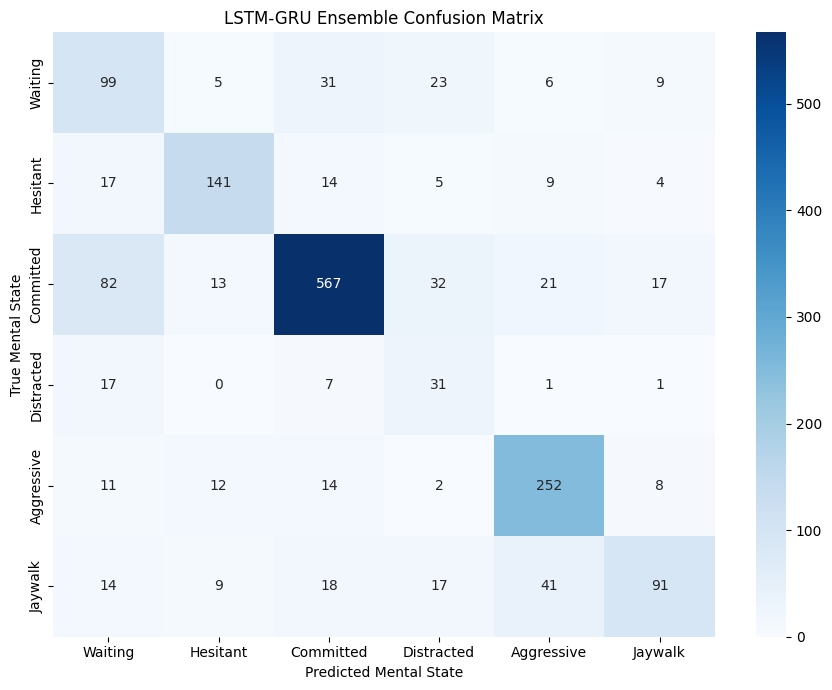

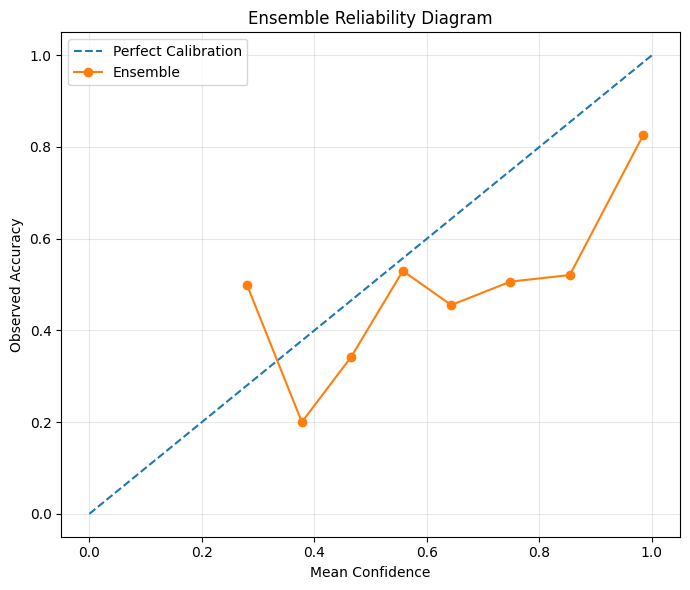


=== PER-CLASS AUC ===
     Class  ROC-AUC  PR-AUC (Average Precision)
   Waiting 0.886830                    0.491113
  Hesitant 0.954536                    0.837682
 Committed 0.931201                    0.925239
Distracted 0.940070                    0.226389
Aggressive 0.970440                    0.858778
   Jaywalk 0.813787                    0.591402

Inference latency: NOT MEASURED (provide predict_one and latency_inputs)

Prediction stability: NOT MEASURED (requires sequence_ids and frame_ids)

FINAL LSTM-GRU ENSEMBLE EVALUATION
Weights: LSTM 40% | GRU 60%
                     Metric    Value
                   Accuracy 0.719683
          Balanced Accuracy 0.659094
                   Macro F1 0.633803
                Weighted F1 0.729289
                        MCC 0.627644
              Cohen's Kappa 0.624632
                   Log Loss 1.071124
     Multiclass Brier Score 0.448100
 Expected Calibration Error 0.164946
          Macro OvR ROC-AUC 0.916144
      Macro OvR PR-AUC

In [34]:

# ============================================================
# LSTM + GRU ENSEMBLE: COMPLETE EVALUATION
# 40% LSTM + 60% GRU
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    log_loss,
    roc_auc_score,
    average_precision_score
)
from sklearn.preprocessing import label_binarize

# ----------------------------
# 1. PREPARE DATA
# ----------------------------

CLASS_NAMES = [
    "Waiting",
    "Hesitant",
    "Committed",
    "Distracted",
    "Aggressive",
    "Jaywalk"
]

N_CLASSES = len(CLASS_NAMES)
LSTM_WEIGHT = 0.40
GRU_WEIGHT = 0.60

y_true = np.asarray(y_test)
if y_true.ndim == 2:
    y_true = np.argmax(y_true, axis=1)
y_true = y_true.astype(int).ravel()

lstm_p = np.asarray(lstm_probs, dtype=float)
gru_p = np.asarray(gru_probs, dtype=float)

assert lstm_p.shape == gru_p.shape
assert lstm_p.shape == (len(y_true), N_CLASSES)
assert np.all(np.isfinite(lstm_p))
assert np.all(np.isfinite(gru_p))
assert np.all((y_true >= 0) & (y_true < N_CLASSES))

# Weighted ensemble
ensemble_probs = (
    LSTM_WEIGHT * lstm_p
    + GRU_WEIGHT * gru_p
)

# Normalize probabilities for numerical safety
ensemble_probs = np.clip(ensemble_probs, 1e-12, None)
ensemble_probs /= ensemble_probs.sum(axis=1, keepdims=True)

ensemble_pred = np.argmax(ensemble_probs, axis=1)

# ----------------------------
# 2. MAIN CLASSIFICATION METRICS
# ----------------------------

accuracy = accuracy_score(y_true, ensemble_pred)
balanced_acc = balanced_accuracy_score(y_true, ensemble_pred)

macro_f1 = f1_score(
    y_true, ensemble_pred,
    average="macro", zero_division=0
)

weighted_f1 = f1_score(
    y_true, ensemble_pred,
    average="weighted", zero_division=0
)

mcc = matthews_corrcoef(y_true, ensemble_pred)
kappa = cohen_kappa_score(y_true, ensemble_pred)

loss = log_loss(
    y_true,
    ensemble_probs,
    labels=np.arange(N_CLASSES)
)

# ----------------------------
# 3. PER-CLASS PRECISION / RECALL / F1
# ----------------------------

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true,
        ensemble_pred,
        labels=np.arange(N_CLASSES),
        zero_division=0
    )
)

class_report = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Support": support
})

print("\n=== PER-CLASS PERFORMANCE ===")
print(class_report.to_string(index=False))

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_true,
    ensemble_pred,
    labels=np.arange(N_CLASSES),
    target_names=CLASS_NAMES,
    zero_division=0
))

# ----------------------------
# 4. CONFUSION MATRIX
# ----------------------------

cm = confusion_matrix(
    y_true,
    ensemble_pred,
    labels=np.arange(N_CLASSES)
)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=ax
)
ax.set_title("LSTM-GRU Ensemble Confusion Matrix")
ax.set_xlabel("Predicted Mental State")
ax.set_ylabel("True Mental State")
plt.tight_layout()
plt.show()

# ----------------------------
# 5. MULTICLASS BRIER SCORE
# ----------------------------

one_hot = np.eye(N_CLASSES)[y_true]

brier = np.mean(
    np.sum(
        (ensemble_probs - one_hot) ** 2,
        axis=1
    )
)

# ----------------------------
# 6. EXPECTED CALIBRATION ERROR
# ----------------------------

def calculate_ece(y, probs, n_bins=10):
    confidence = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    correctness = (predictions == y).astype(float)

    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        if i == 0:
            mask = (
                (confidence >= edges[i])
                & (confidence <= edges[i + 1])
            )
        else:
            mask = (
                (confidence > edges[i])
                & (confidence <= edges[i + 1])
            )

        if np.any(mask):
            bin_acc = np.mean(correctness[mask])
            bin_conf = np.mean(confidence[mask])

            ece += np.mean(mask) * abs(
                bin_acc - bin_conf
            )

    return float(ece)

ece = calculate_ece(y_true, ensemble_probs)

# Reliability diagram
confidence = ensemble_probs.max(axis=1)
correctness = (ensemble_pred == y_true).astype(float)

bin_edges = np.linspace(0, 1, 11)
bin_confidences = []
bin_accuracies = []

for i in range(10):
    if i == 0:
        mask = (
            (confidence >= bin_edges[i])
            & (confidence <= bin_edges[i + 1])
        )
    else:
        mask = (
            (confidence > bin_edges[i])
            & (confidence <= bin_edges[i + 1])
        )

    if mask.any():
        bin_confidences.append(confidence[mask].mean())
        bin_accuracies.append(correctness[mask].mean())

plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], "--", label="Perfect Calibration")
plt.plot(
    bin_confidences,
    bin_accuracies,
    marker="o",
    label="Ensemble"
)
plt.xlabel("Mean Confidence")
plt.ylabel("Observed Accuracy")
plt.title("Ensemble Reliability Diagram")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ----------------------------
# 7. ROC-AUC AND PR-AUC
# ----------------------------

roc_auc_per_class = []
pr_auc_per_class = []

for i in range(N_CLASSES):
    binary_true = (y_true == i).astype(int)

    # AUC requires positive and negative examples
    if np.unique(binary_true).size < 2:
        roc_auc_per_class.append(np.nan)
        pr_auc_per_class.append(np.nan)
        continue

    roc_auc_per_class.append(
        roc_auc_score(
            binary_true,
            ensemble_probs[:, i]
        )
    )

    pr_auc_per_class.append(
        average_precision_score(
            binary_true,
            ensemble_probs[:, i]
        )
    )

auc_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "ROC-AUC": roc_auc_per_class,
    "PR-AUC (Average Precision)": pr_auc_per_class
})

print("\n=== PER-CLASS AUC ===")
print(auc_df.to_string(index=False))

macro_roc_auc = np.nanmean(roc_auc_per_class)
macro_pr_auc = np.nanmean(pr_auc_per_class)

# ----------------------------
# 8. INFERENCE LATENCY (OPTIONAL)
# ----------------------------

# Set this to a callable that performs BOTH model predictions
# for one sample and returns the blended probabilities.
#
# Example:
# def predict_one(sample):
#     lp = lstm_model.predict(sample, verbose=0)
#     gp = gru_model.predict(sample, verbose=0)
#     return 0.40 * lp + 0.60 * gp
#
# This assumes sample is already scaled and shaped correctly.

predict_one = None

# Set to actual model input array if available,
# e.g. X_test_scaled, with shape (N, 30, 36).
latency_inputs = None

latency_ms = np.array([])

if predict_one is not None and latency_inputs is not None:
    samples = np.asarray(latency_inputs)

    # Warm up model execution
    for i in range(min(5, len(samples))):
        predict_one(samples[i:i+1])

    measurements = []

    for i in range(min(100, len(samples))):
        start = time.perf_counter()
        predict_one(samples[i:i+1])
        elapsed = (time.perf_counter() - start) * 1000
        measurements.append(elapsed)

    latency_ms = np.asarray(measurements)

    print("\n=== INFERENCE LATENCY ===")
    print(f"Mean: {latency_ms.mean():.2f} ms")
    print(f"P95 : {np.percentile(latency_ms, 95):.2f} ms")
else:
    print(
        "\nInference latency: NOT MEASURED "
        "(provide predict_one and latency_inputs)"
    )

# ----------------------------
# 9. PREDICTION STABILITY (OPTIONAL)
# ----------------------------

# Predictions must be grouped in their original time order.
# Do NOT use shuffled test-set order.
#
# Example:
# sequence_ids = np.array([...])  # scenario/run identifier
# frame_ids = np.array([...])     # chronological frame index
#
# Both arrays must align with ensemble_pred.

sequence_ids = None
frame_ids = None

stability = np.nan

if sequence_ids is not None and frame_ids is not None:
    stability_df = pd.DataFrame({
        "sequence": sequence_ids,
        "frame": frame_ids,
        "prediction": ensemble_pred
    })

    stability_df = stability_df.sort_values(
        ["sequence", "frame"]
    )

    previous = stability_df.groupby(
        "sequence"
    )["prediction"].shift()

    valid = previous.notna()

    if valid.any():
        switches = (
            stability_df.loc[valid, "prediction"].to_numpy()
            != previous[valid].to_numpy()
        )

        switch_rate = switches.mean()
        stability = 1 - switch_rate

        print("\n=== PREDICTION STABILITY ===")
        print(f"Switch rate: {switch_rate:.4f}")
        print(f"Stability:   {stability:.4f}")
    else:
        print("\nPrediction stability: insufficient frames")
else:
    print(
        "\nPrediction stability: NOT MEASURED "
        "(requires sequence_ids and frame_ids)"
    )

# ----------------------------
# 10. COMPLETE SUMMARY
# ----------------------------

summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1",
        "Weighted F1",
        "MCC",
        "Cohen's Kappa",
        "Log Loss",
        "Multiclass Brier Score",
        "Expected Calibration Error",
        "Macro OvR ROC-AUC",
        "Macro OvR PR-AUC (AP)",
        "Mean Inference Latency (ms)",
        "P95 Inference Latency (ms)",
        "Prediction Stability"
    ],
    "Value": [
        accuracy,
        balanced_acc,
        macro_f1,
        weighted_f1,
        mcc,
        kappa,
        loss,
        brier,
        ece,
        macro_roc_auc,
        macro_pr_auc,
        latency_ms.mean() if len(latency_ms) else np.nan,
        np.percentile(latency_ms, 95) if len(latency_ms) else np.nan,
        stability
    ]
})

print("\n" + "=" * 55)
print("FINAL LSTM-GRU ENSEMBLE EVALUATION")
print("Weights: LSTM 40% | GRU 60%")
print("=" * 55)
print(summary.to_string(index=False))

# ----------------------------
# 11. SAVE RESULTS
# ----------------------------

from pathlib import Path

output_dir = Path(
    str(globals().get("MODEL_PATH", "."))
)
output_dir.mkdir(parents=True, exist_ok=True)

summary.to_csv(
    output_dir / "ensemble_metrics.csv",
    index=False
)

class_report.to_csv(
    output_dir / "ensemble_per_class_metrics.csv",
    index=False
)

auc_df.to_csv(
    output_dir / "ensemble_auc_metrics.csv",
    index=False
)

pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    output_dir / "ensemble_confusion_matrix.csv"
)

print("\nEvaluation results saved to:", output_dir)
